# Lab 4 — Leakage-safe classification and regression pipelines
Experiment A predicts **whether a ticket is escalated**. Experiment B predicts **resolution time in hours** . 

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

SEED = 42
clf_df = pd.read_csv("data/classification_escalation.csv")
reg_df = pd.read_csv("data/resolution_time_regression.csv")
display(clf_df.head(), reg_df.head())

,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,T0000,2.0,15.0,Medium,Email,61.818896,0
1,T0001,9.0,6.0,Critical,Chat,110.024317,0
2,T0002,10.0,8.0,High,Phone,36.311244,0
3,T0003,2.0,1.0,Medium,Phone,85.127855,0
4,T0004,8.0,14.0,Medium,Chat,18.225059,0


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
0,R0000,7.0,10.0,Medium,Chat,32.638377,8.38724
1,R0001,4.0,15.0,Medium,Chat,45.273760,0.50000
2,R0002,4.0,13.0,Low,Portal,44.878323,0.50000
3,R0003,1.0,10.0,High,Phone,40.095034,0.50000
4,R0004,3.0,15.0,Low,Portal,47.451134,0.50000


## 0. Quick data check
We look at shape, missing values and the target before modelling. Nothing is fitted here, so nothing can leak.

In [2]:
print(clf_df.shape, reg_df.shape)
print("Missing values (classification):\n", clf_df.isna().sum(), "\n")
print("Missing values (regression):\n", reg_df.isna().sum(), "\n")
print("Escalation rate:", clf_df["escalated"].mean().round(3))
print(reg_df["resolution_time_hours"].describe().round(2))
print("Rows sitting exactly at the 0.5h floor:", (reg_df["resolution_time_hours"] == 0.5).sum())

(900, 7) (800, 7)
Missing values (classification):
 ticket_id                  0
complexity_score          22
team_experience_years     36
priority                  13
channel                    9
customer_tenure_months    31
escalated                  0
dtype: int64 

Missing values (regression):
 ticket_id                  0
complexity_score          16
team_experience_years     24
priority                   0
channel                    0
customer_tenure_months    20
resolution_time_hours      0
dtype: int64 

Escalation rate: 0.212
count    800.00
mean       5.87
std        4.14
min        0.50
25%        2.63
50%        5.39
75%        8.35
max       27.49
Name: resolution_time_hours, dtype: float64
Rows sitting exactly at the 0.5h floor: 72


# Experiment A — Classification

### A1. Features, target and stratified split
`ticket_id` is an identifier `stratify=y` keeps the ~21% escalation rate the same in train and test.

In [8]:
y = clf_df["escalated"]
X = clf_df.drop(columns=["ticket_id", "escalated"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("train:", X_train.shape, "escalation rate", round(y_train.mean(), 3))
print("test :", X_test.shape,  "escalation rate", round(y_test.mean(), 3))

train: (720, 5) escalation rate 0.212
test : (180, 5) escalation rate 0.211


### A2. Preprocessing (inside the pipeline)
- numeric: median imputation (robust to skew), then standard scaling (matters for k-NN and logistic regression)
- categorical: most-frequent imputation, then one-hot encoding (`handle_unknown='ignore'` so unseen categories never crash)

In [26]:
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print("numeric:", num_cols, "| categorical:", cat_cols)

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc",  StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh",  OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])

numeric: ['complexity_score', 'team_experience_years', 'customer_tenure_months'] | categorical: ['priority', 'channel']


### A3. Compare 3 models with identical 5-fold StratifiedKFold CV (primary metric F1)
One `cv` object is reused so every model sees exactly the same folds. CV runs on the **training set only**.

In [10]:
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=SEED),
    "kNN":                KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=SEED),
}
rows = []
for name, m in models.items():
    pipe = Pipeline([("pre", make_preprocessor()), ("model", m)])
    s = cross_validate(pipe, X_train, y_train, cv=cv_clf,
                       scoring=["f1", "precision", "recall", "accuracy"])
    rows.append({"model": name,
                 "F1 mean": s["test_f1"].mean(), "F1 std": s["test_f1"].std(ddof=1),
                 "precision": s["test_precision"].mean(), "recall": s["test_recall"].mean(),
                 "accuracy": s["test_accuracy"].mean(),
                 "fold F1s": np.round(s["test_f1"], 3)})
cv_table_A = pd.DataFrame(rows).set_index("model")
display(cv_table_A.round(3))

,F1 mean,F1 std,precision,recall,accuracy,fold F1s
model,,,,,,
LogisticRegression,0.393,0.070,0.624,0.288,0.812,"[0.391, 0.326, 0.364, 0.372, 0.511]"
kNN,0.361,0.056,0.562,0.268,0.800,"[0.367, 0.326, 0.426, 0.286, 0.4]"
DecisionTree,0.331,0.065,0.318,0.347,0.704,"[0.4, 0.23, 0.323, 0.373, 0.328]"


### A4. Tune every candidate (GridSearchCV, same folds, scoring = F1)
Search spaces are small on purpose: with only 720 training rows, big grids mostly fit noise. `class_weight='balanced'` is included because only ~21% of tickets are escalations.

In [11]:
grids = {
    "LogisticRegression": (LogisticRegression(max_iter=1000, random_state=SEED),
        {"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]}),
    "kNN": (KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 7, 11, 15, 21], "model__weights": ["uniform", "distance"]}),
    "DecisionTree": (DecisionTreeClassifier(random_state=SEED),
        {"model__max_depth": [2, 3, 4, 5, 6, 8, None],
         "model__min_samples_leaf": [1, 5, 10, 20],
         "model__class_weight": [None, "balanced"]}),
}
searches, tuned_rows = {}, []
for name, (m, grid) in grids.items():
    gs = GridSearchCV(Pipeline([("pre", make_preprocessor()), ("model", m)]),
                      grid, cv=cv_clf, scoring="f1").fit(X_train, y_train)
    searches[name] = gs
    i = gs.best_index_
    tuned_rows.append({"model": name, "best params": gs.best_params_,
                       "CV F1 mean": gs.best_score_,
                       "CV F1 std": gs.cv_results_["std_test_score"][i]})
display(pd.DataFrame(tuned_rows).set_index("model"))
best_name = max(searches, key=lambda k: searches[k].best_score_)
print("Selected:", best_name)

,best params,CV F1 mean,CV F1 std
model,,,
LogisticRegression,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.519993,0.042344
kNN,"{'model__n_neighbors': 3, 'model__weights': 'u...",0.390646,0.064431
DecisionTree,"{'model__class_weight': 'balanced', 'model__ma...",0.498196,0.044637


Selected: LogisticRegression


### A5. Final evaluation on the test set — **once**

In [16]:
final_clf = searches[best_name].best_estimator_   # already refit on all training data
pred = final_clf.predict(X_test)
print(classification_report(y_test, pred, target_names=["not escalated", "escalated"]))
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("Always-predict-'no escalation' accuracy:", round(1 - y_test.mean(), 3))

               precision    recall  f1-score   support

not escalated       0.91      0.82      0.87       142
    escalated       0.52      0.71      0.60        38

     accuracy                           0.80       180
    macro avg       0.72      0.77      0.73       180
 weighted avg       0.83      0.80      0.81       180

TN=117  FP=25  FN=11  TP=27
Always-predict-'no escalation' accuracy: 0.789


In [ ]:
# What did the model learn? (logistic regression coefficients on scaled / one-hot features)
names = final_clf.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(final_clf.named_steps["model"].coef_[0], index=names).sort_values()
display(coefs.round(3))

# Experiment B — Regression

### B1. Split and outlook on the target
We predict `resolution_time_hours`. The target is right-skewed, has a hard floor at 0.5 h and a few very long tickets (outliers). We keep them: they are real tickets, and the model will meet them in production.

IQR outlier fence: 16.92 h -> 10 tickets above it; max = 27.49 h


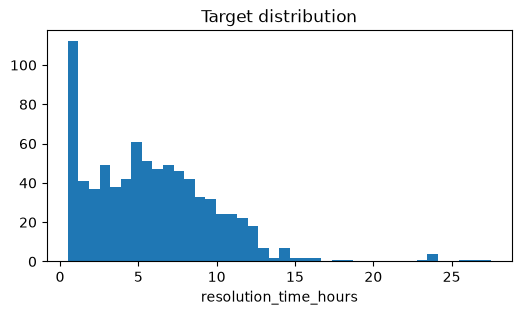

In [15]:
yb = reg_df["resolution_time_hours"]
Xb = reg_df.drop(columns=["ticket_id", "resolution_time_hours"])
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.20, random_state=SEED)

q1, q3 = yb.quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)
print(f"IQR outlier fence: {upper:.2f} h -> {(yb > upper).sum()} tickets above it; max = {yb.max():.2f} h")
plt.figure(figsize=(6,3)); plt.hist(yb, bins=40); plt.xlabel("resolution_time_hours"); plt.title("Target distribution"); plt.show()

### B2. Compare linear, ridge and tree regression (5-fold KFold, MAE)
The same preprocessing is used and is refit inside every fold.

In [24]:
num_b = Xb.select_dtypes(include="number").columns.tolist()
cat_b = [c for c in Xb.columns if c not in num_b]
def make_pre_b():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_b),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_b)])

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_models = {"LinearRegression": LinearRegression(), "Ridge (alpha=1)": Ridge(alpha=1.0),
              "DecisionTree (default)": DecisionTreeRegressor(random_state=SEED)}
rows = []
for name, m in reg_models.items():
    s = cross_validate(Pipeline([("pre", make_pre_b()), ("model", m)]), Xb_train, yb_train, cv=cv_reg,
                       scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error"])
    mae, rmse = -s["test_neg_mean_absolute_error"], -s["test_neg_root_mean_squared_error"]
    rows.append({"model": name, "MAE mean": mae.mean(), "MAE std": mae.std(ddof=1),
                 "RMSE mean": rmse.mean(), "RMSE std": rmse.std(ddof=1), "fold MAEs": np.round(mae, 3)})
display(pd.DataFrame(rows).set_index("model").round(3))

,MAE mean,MAE std,RMSE mean,RMSE std,fold MAEs
model,,,,,
LinearRegression,2.035,0.192,2.961,0.653,"[2.342, 1.817, 1.965, 2.044, 2.008]"
Ridge (alpha=1),2.035,0.192,2.960,0.652,"[2.341, 1.816, 1.967, 2.045, 2.006]"
DecisionTree (default),3.235,0.061,4.582,0.424,"[3.23, 3.168, 3.216, 3.336, 3.226]"


### B3. Tune ridge `alpha` and tree `max_depth` / `min_samples_leaf`

In [27]:
reg_grids = {
    "Ridge": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    "DecisionTree": (DecisionTreeRegressor(random_state=SEED),
                     {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
                      "model__min_samples_leaf": [1, 5, 10, 20]}),
}
reg_search, rows = {}, []
for name, (m, grid) in reg_grids.items():
    gs = GridSearchCV(Pipeline([("pre", make_pre_b()), ("model", m)]), grid,
                      cv=cv_reg, scoring="neg_mean_absolute_error").fit(Xb_train, yb_train)
    reg_search[name] = gs; i = gs.best_index_
    rows.append({"model": name, "best params": gs.best_params_,
                 "CV MAE mean": -gs.best_score_, "CV MAE std": gs.cv_results_["std_test_score"][i]})
display(pd.DataFrame(rows).set_index("model"))
best_reg = max(reg_search, key=lambda k: reg_search[k].best_score_)   # best_score_ is negative MAE, so max = lowest MAE
print("Selected:", best_reg)

,best params,CV MAE mean,CV MAE std
model,,,
Ridge,{'model__alpha': 0.1},2.035118,0.171627
DecisionTree,"{'model__max_depth': 6, 'model__min_samples_le...",2.364259,0.089054


Selected: Ridge


### B4. Final test evaluation — once

In [28]:
final_reg = reg_search[best_reg].best_estimator_
p = final_reg.predict(Xb_test)
err = yb_test.values - p
print(f"Test MAE : {mean_absolute_error(yb_test, p):.3f} h")
print(f"Test RMSE: {np.sqrt(mean_squared_error(yb_test, p)):.3f} h")
print(f"Median absolute error: {np.median(np.abs(err)):.3f} h | worst miss: {np.abs(err).max():.2f} h")
print("Baseline (always predict training median) MAE:",
      round(mean_absolute_error(yb_test, np.full(len(yb_test), yb_train.median())), 3))

# Why MAE and RMSE can disagree: a few large misses dominate squared error
k = int(np.ceil(0.05 * len(err)))
print(f"Worst 5% of tickets ({k}) = {np.sort(err**2)[-k:].sum() / (err**2).sum():.0%} of total squared error,",
      f"but only {np.sort(np.abs(err))[-k:].sum() / np.abs(err).sum():.0%} of total absolute error")

Test MAE : 2.230 h
Test RMSE: 3.403 h
Median absolute error: 1.699 h | worst miss: 21.11 h
Baseline (always predict training median) MAE: 3.273
Worst 5% of tickets (8) = 61% of total squared error, but only 23% of total absolute error


## Report
## 1. Problem framing
I predict whether a service ticket will be escalated (`escalated` = 1) from five fields: complexity score, team experience, priority, channel and customer tenure. The label is discrete, so this is binary classification. The positive class is "escalated", the event we want to catch. Only 20.7% of the 900 tickets are escalated, and a missed escalation is treated as five times as costly as a needless one (cost = 5×FN + 1×FP). The goal is therefore a good cost-aware decision rule, not just a high score.

## 2. Preprocessing and why
- **Numeric columns:** median imputation, then standardisation. The median is robust to outliers (for example tenure up to 97 months), and scaling is needed for k-NN and helps logistic regression.
- **Categorical columns (priority, channel):** most-frequent imputation, then one-hot encoding with `handle_unknown="ignore"`, so an unseen category at prediction time does not crash the model.
- Missing values were 3.4% (experience), 2.0% (priority) and 2.4% (tenure). They were imputed rather than dropped because dropping rows would lose data and could bias the sample.

## 3. Validation strategy and leakage prevention
The data were split 75/25 (`random_state=42`, stratified), giving 675 training and 225 test tickets. All model selection used **stratified 5-fold cross-validation on the training set only** (shuffled, seed 42). Each fold holds about 135 tickets with about 28 escalations. The test set was held back for the final check. Preprocessing sits inside a scikit-learn `Pipeline`, so imputation values, scaling statistics and encodings are learned only from the training part of each fold. Nothing from validation or test rows leaks into fitting.

## 4. Candidate models and search space
- Majority-class baseline (reference only)
- Logistic regression (default regularisation)
- Linear Discriminant Analysis
- k-NN, with k searched over {5, 9, 15, 21, 31} by grid search, scored on F1

Only k-NN was tuned, because the assignment specified that search.

## 5. Cross-validation results (training set, mean of 5 folds)

| Model | Precision | Recall | F1 | F1 std | ROC-AUC |
|---|---|---|---|---|---|
| Majority baseline | 0.000 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic regression | 0.539 | 0.164 | 0.248 | 0.075 | 0.744 |
| LDA | 0.554 | 0.179 | 0.266 | 0.089 | 0.743 |
| k-NN (k=15) | 0.458 | 0.100 | 0.160 | 0.065 | 0.681 |

k-NN tuning (mean CV F1): k=5 0.243, k=9 0.198, k=15 0.160, k=21 0.146, k=31 0.112. The best k is 5, at the edge of the grid.

## 6. Final test result
At the default 0.5 threshold, logistic regression gets precision 0.75, recall 0.196, F1 0.31 and ROC-AUC 0.811. It catches only 9 of 46 escalations (accuracy 0.822, versus 0.796 for the baseline).

With the cost-based threshold chosen on **training out-of-fold predictions (0.15)**, the test result is TP 38, FP 76, FN 8, TN 103: precision 0.33, recall 0.83, F1 0.48, cost 116 (0.52 per ticket). Escalating nothing costs 230 and escalating everything costs 179.

## 7. Final model justification
I choose **logistic regression with a threshold of about 0.15**. It ties with LDA on every metric, is simple to explain, outputs probabilities directly, and beats k-NN clearly. The break-even probability under 5:1 costs is 1/6 ≈ 0.17, and the threshold picked from training data (0.15) agrees with it.

## 8. Limitations
- The data are synthetic: 900 rows, and only 46 positives in the test set. One ticket moves recall by about 2 points.
- Discrimination is moderate (AUC about 0.74 to 0.81), so many escalations cannot be predicted from these five fields.
- The 5:1 cost ratio is illustrative, and the threshold rule assumes calibrated probabilities, which I did not check.
- The test set was also used to compare models and to sweep thresholds (as the assignment required). The test-optimal threshold of 0.20 (cost 98) is therefore optimistic, and 116 is the more honest estimate.
- A cost-driven threshold means many false alarms: about two thirds of flagged tickets are not escalated.

## 9. Reflection questions

**1. Why stratify the classification split?** Only about one ticket in five is escalated. A random split could give the test set a noticeably different share of escalations, so scores would reflect the split and not the model. Stratifying keeps the rate the same in train (20.7%) and test (20.4%) and keeps every CV fold usable.

**2. Why must preprocessing be inside the pipeline?** Imputation values, scaling means and category lists are learned from data. If they are fitted on the full dataset, information from validation or test rows leaks into training and the scores look better than they really are. Inside a pipeline, they are refit on the training part of every fold, exactly as they would be in production.

**3. What does fold variability tell you?** The F1 standard deviation is about 0.07 to 0.09 across folds of about 28 positives each. That is as large as the gaps between most candidates: LR and LDA differ by 0.018, and k=5 versus k=9 differ by 0.045. Those differences are within noise, so I treat LR and LDA as equal and do not read much into the exact best k.

**4. Why evaluate the test set only once?** Each time we look at test results and change something, the test set becomes part of model selection and stops being an unbiased estimate. In this notebook the threshold sweep on test (the assignment's task) already made the 98 figure optimistic. The right procedure is to choose model and threshold using training data only, then score once on the test set and report that number.

**5. What deployment constraints might change my choice?** Prediction latency and memory (k-NN keeps all training data and is slow to score), the need to explain decisions to staff or customers (favours logistic regression), a requirement for calibrated probabilities, how often data drift forces retraining, missing values arriving at prediction time, fairness or regulatory rules about customer groups, and the actual capacity of senior staff to handle the extra flagged tickets. The last one could force a higher threshold than the cost model suggests.